# Endogenous adaptation investment 

### Teoria implementata

La soglia $x^F$ non è più fissa ma dipende dalla ricchezza aggregata (equazione
"threshold_moving" del `.tex`):

$$
x_t^F = x^F_0 + \frac{f}{1-\alpha}\big(\mathbf{X}_t - \mathbf{X}_0\big) \qquad (\star)
$$

dove $\mathbf{X}_t = \int x \, dD_t(x)$ è la ricchezza aggregata attesa al tempo $t$ (nel
codice: la media della ricchezza individuale, dato che la massa totale di agenti è 1).

**Problema:** $(\star)$ è illimitata in $\mathbf{X}_t$ e può diventare negativa, il che non ha
senso dato che $x^F=F/(1+\mu)$ e $F\ge0$ è un costo strutturale. `simulations_endogenous.py`
offre quindi due specificazioni formalmente valide per imporre $x_t^F\ge0$, selezionabili con
`threshold_mode`:

- **`'log'` (DEFAULT)** — riparametrizzazione moltiplicativa/log-lineare
  $$x_t^F = x^F_0 \cdot \exp\!\Big[\tfrac{f}{1-\alpha}(\mathbf{X}_t-\mathbf{X}_0)\Big]$$
  positiva per costruzione, in forma chiusa esatta, coincide al primo ordine con $(\star)$.
- **`'corner'` (alternativa)** — soluzione d'angolo applicata come **ricorsione periodo per
  periodo**: $x^F_{t+1}=\max\{0,\,x^F_t+\tfrac{f}{1-\alpha}(\mathbf{X}_{t+1}-\mathbf{X}_t)\}$.

Sono discusse più in dettaglio, con le relative motivazioni formali, più avanti in questo
notebook (sezione "Le due specificazioni di $x_t^F$").


In [1]:
import sys, os
# Se questo notebook si trova nella stessa cartella dei file .py del progetto,
# la riga seguente non è necessaria. Altrimenti, aggiornare il path come nel
# notebook 02_shock_dynamics_final.ipynb:
sys.path.append("/Users/sofiacattaneo/tesi-inequality/src")
sys.path.append(os.getcwd())


In [2]:
import numpy as np
import matplotlib.pyplot as plt

import parameters as _par
from conditions import *
from functions import *
from distributions import *
from dynamics import *
from simulations_det import simulate_det
from simulations_shock import simulate_shock
from simulations_endogenous import (simulate_endogenous_det,
                                     simulate_endogenous_shock,
                                     endogenous_threshold_log,
                                     endogenous_threshold_corner_step,
                                     endogenous_threshold_naive_clip,
                                     empirical_H_map)

np.random.seed(0)


### Parametri di base

Uso gli stessi parametri strutturali di `parameters.py`. Il diagnostico `print_regime_summary` mi dice dove si trova $n^*$ per QUESTI parametri, nel caso
di soglia fissa — mi serve come riferimento per scegliere le distribuzioni iniziali degli
scenari A e B qui sotto.

In [4]:
print_regime_summary()


╔══ PARAMETRI CORRENTI ══╗
  p = 0.5   q = 0.5   gamma_p = 0.4   gamma_up = 0.6
  A_p_bar = 1.7   A_up_bar = 1.2   xF (F) = 0.3333333333333333


╔══ ANALISI TEORICA (valori attesi) ══╗
  n* calcolato con E[A_p] = A_p_bar*(1-p*gamma_p)*(1+n_p)
───────────────────────────────────────────────────────
 MODE: EXPECTED
───────────────────────────────────────────────────────
  Tipo ramo sinistro : poor_attractor
  Tipo ramo destro : phase_transition
  n*               = 0.1954  (in [0,1] )
  a_R(n_p = 0)     = 0.7210
  a_R(n_p = n*)    = 1.0000
  a_R(n_p = 1)     = 2.1490
  Regime n_p < n*  : poor_and_rich_attractor
  Regime n_p > n*  : poor_attractor_and_explosion

╔══ ANALISI SIMULATIVA (produttività reale) ══╗
  n* calcolato con la produttività effettiva.
  Ad ogni step la simulazione si trova in uno
  dei due casi seguenti con prob (1-p) e p.

───────────────────────────────────────────────────────
 MODE: NOSHOCK
───────────────────────────────────────────────────────
  Tipo ramo sinistro

## Le due specificazioni di $x_t^F$: `'log'` vs `'corner'`

Prima di passare agli scenari, verifico concretamente la differenza fra le due specificazioni
positive discusse sopra, e il motivo per cui la versione "chiusa-poi-troncata"
(`endogenous_threshold_naive_clip`, non usata di default, tenuta solo per confronto) NON è una
corretta implementazione della soluzione d'angolo.

In [5]:
# Esempio numerico minimale: X0=1, xF0=1, f/(1-alpha)=1, e una traiettoria di X che scende
# molto (X2=-3, ipotetico) e poi risale (X3=1).
X0, xF0, f_over_1ma = 1.0, 1.0, 1.0
alpha_toy = 0.0  # cosi' f_adapt/(1-alpha_toy) = f_adapt = f_over_1ma
Xs = [1.0, 1.0, -3.0, 1.0]

naive = [endogenous_threshold_naive_clip(Xt, X0, xF0, f_over_1ma, alpha_toy) for Xt in Xs]

xF_prev, X_prev = xF0, X0
corner = [xF0]
for Xt in Xs[1:]:
    xF_t = endogenous_threshold_corner_step(xF_prev, X_prev, Xt, f_over_1ma, alpha_toy)
    corner.append(xF_t)
    xF_prev, X_prev = xF_t, Xt

log_form = [endogenous_threshold_log(Xt, X0, xF0, f_over_1ma, alpha_toy) for Xt in Xs]

print("X_t         :", Xs)
print("naive_clip  :", [round(v, 3) for v in naive])
print("corner (ric):", [round(v, 3) for v in corner])
print("log         :", [round(v, 3) for v in log_form])


X_t         : [1.0, 1.0, -3.0, 1.0]
naive_clip  : [1.0, 1.0, 0.0, 1.0]
corner (ric): [1.0, 1.0, 0.0, 4.0]
log         : [1.0, 1.0, 0.018, 1.0]


A $t=3$, dopo che $X$ è tornato al livello iniziale, `naive_clip` dà $x_3^F=1$ (come se la
discesa a $X_2=-3$ non fosse mai avvenuta), mentre la ricorsione `corner` corretta dà $x_3^F=4$
(la soglia resta "bloccata" a zero durante la discesa e poi riparte da lì, accumulando un ritardo
reale). `log` non ha mai bisogno di troncare, ed è l'unica delle tre a restare positiva e in
forma chiusa esatta indipendentemente dal percorso di $X$.

Guardiamo ora la differenza su una simulazione vera (non un esempio giocattolo), nello stesso
scenario esplosivo che uso più sotto come Scenario B.

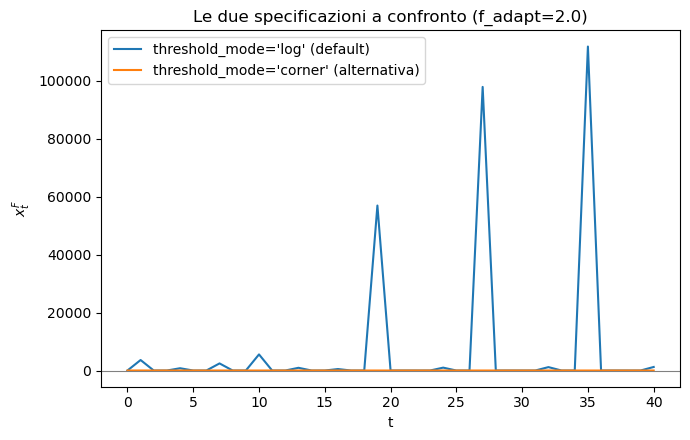

In [26]:
N_demo, T_demo, L_demo, f_demo_cmp = _par.N, 40, 3.0, 2.0

np.random.seed(2)
_, xF_log, _, _ = simulate_endogenous_det(
    lambda N: uniform_initial(N, low=0, high=L_demo), update_wealth, T_demo, f_demo_cmp,
    N=N_demo, threshold_mode='log')

np.random.seed(2)
_, xF_corner, _, _ = simulate_endogenous_det(
    lambda N: uniform_initial(N, low=0, high=L_demo), update_wealth, T_demo, f_demo_cmp,
    N=N_demo, threshold_mode='corner')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(xF_log, label="threshold_mode='log' (default)")
ax.plot(xF_corner, label="threshold_mode='corner' (alternativa)")
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xlabel("t"); ax.set_ylabel(r"$x_t^F$")
ax.set_title(fr"Le due specificazioni a confronto (f_adapt={f_demo_cmp})")
ax.legend()
plt.tight_layout()
plt.show()


Sono due dinamiche legittime ma diverse: `'log'` è liscia (nessun kink) e non tocca mai
esattamente zero; `'corner'` può restare incollata a zero per più periodi consecutivi quando la
ricchezza aggregata scende, ed è per costruzione l'analogo discreto di un vincolo di
Kuhn–Tucker applicato periodo per periodo — coerente con la letteratura sui *piecewise-smooth
dynamical systems* (di Bernardo et al.), dato che introduce un kink
esplicito nella dinamica di $x_t^F$.

## Scenario A — $n_0^P < n^*$

Con i parametri di default, $n^*\approx 0.195$ (caso "expected"). Parto da una distribuzione
iniziale uniforme concentrata su valori bassi ($L=0.4 < x^F_0$ circa), in modo che
$n_0^P < n^*$: con soglia FISSA il sistema converge al regime a due attrattori
(`poor_and_rich_attractor`, si veda `conditions.regime`). Voglio vedere cosa cambia quando la
soglia diventa endogena (specificazione `'log'`, default), per diversi valori di $f_{adapt}$.

In [ ]:
from dynamics import update_wealth
N = _par.N
T = 60
L_A = 0.4          # distribuzione iniziale uniforme su [0, L_A]
f_values_A = [0.0, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0]

results_A = {}
for f_adapt in f_values_A:
    np.random.seed(1)   # stesso seed => stessa distribuzione iniziale campionata
    history, xF_hist, np_hist, X_hist = simulate_endogenous_det(
        lambda N: uniform_initial(N, low=0, high=L_A),
        update_wealth, T, f_adapt, N=N)
    results_A[f_adapt] = dict(history=history, xF=xF_hist, n_p=np_hist, X=X_hist)
    print(f"f_ad={f_adapt:5.2f}  n_p0={np_hist[0]:.3f}  n_p_final={np_hist[-1]:.3f}  "
          f"xF0={xF_hist[0]:.3f}  xF_final={xF_hist[-1]:6.4g}  "  
          f"X_init={X_hist[0]:.4g}  X_final={X_hist[-1]:.4g}")


f_ad= 0.00  n_p0=0.167  n_p_final=0.167  xF0=0.333  xF_final=0.3333  X_init=0.1997  X_final=0.8989
f_ad= 0.02  n_p0=0.167  n_p_final=0.167  xF0=0.333  xF_final=0.3469  X_init=0.1997  X_final=0.8989
f_ad= 0.05  n_p0=0.167  n_p_final=0.167  xF0=0.333  xF_final=0.3683  X_init=0.1997  X_final=0.8989
f_ad= 0.10  n_p0=0.167  n_p_final=0.167  xF0=0.333  xF_final= 0.407  X_init=0.1997  X_final=0.8989
f_ad= 0.20  n_p0=0.167  n_p_final=0.167  xF0=0.333  xF_final= 0.497  X_init=0.1997  X_final=0.8989
f_ad= 0.50  n_p0=0.167  n_p_final=0.167  xF0=0.333  xF_final= 0.905  X_init=0.1997  X_final=0.8989
f_ad= 1.00  n_p0=0.167  n_p_final=0.167  xF0=0.333  xF_final= 2.457  X_init=0.1997  X_final=0.8989
f_ad= 2.00  n_p0=0.167  n_p_final=0.086  xF0=0.333  xF_final=0.5612  X_init=0.1997  X_final=0.2909


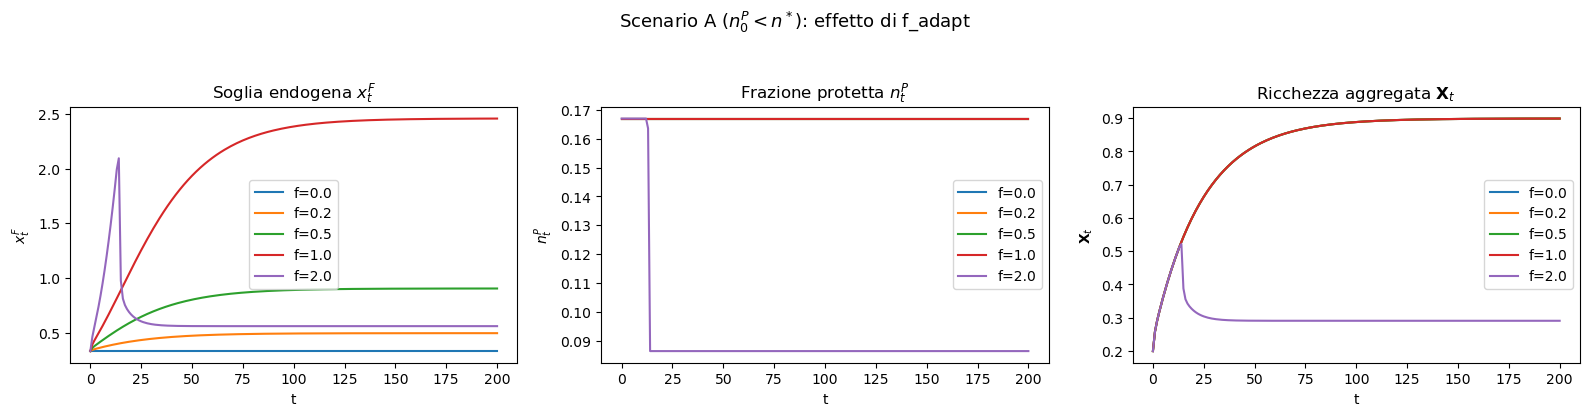

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

plot_subset_A = [0.0, 0.2, 0.5, 1.0, 2.0]
for f_adapt in plot_subset_A:
    r_ = results_A[f_adapt]
    axes[0].plot(r_['xF'], label=f"f={f_adapt}")
    axes[1].plot(r_['n_p'], label=f"f={f_adapt}")
    axes[2].plot(r_['X'],  label=f"f={f_adapt}")

axes[0].set_title(r"Soglia endogena $x_t^F$")
axes[0].set_xlabel("t"); axes[0].set_ylabel(r"$x_t^F$"); axes[0].legend()

axes[1].set_title(r"Frazione protetta $n_t^P$")
axes[1].set_xlabel("t"); axes[1].set_ylabel(r"$n_t^P$"); axes[1].legend()

axes[2].set_title(r"Ricchezza aggregata $\mathbf{X}_t$")
axes[2].set_xlabel("t"); axes[2].set_ylabel(r"$\mathbf{X}_t$"); axes[2].legend()

fig.suptitle("Scenario A ($n_0^P < n^*$): effetto di f_adapt", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


**Osservazione (empirica, verificata numericamente su questa run, modalità `'log'` — non un
risultato dimostrato nel `.tex`):** per $f_{adapt}\le 1.0$ le traiettorie di $n_t^P$ e
$\mathbf{X}_t$ sono **esattamente identiche** a quelle a soglia fissa ($f_{adapt}=0$), anche se
$x_t^F$ cresce visibilmente — solo $x_t^F$ si muove, il resto della dinamica no. La ragione è
coerente con la sottosezione "Evolution of an initial uniform distribution" del `.tex`: dopo il
primo passo la distribuzione si separa in due blocchi con un "gap" $\Delta_1=(a_R-a_L)x_0^F$
privo di massa fra il ramo povero e quello ricco; finché $x_t^F$ resta dentro questo gap, la
classificazione $x_i \gtrless x_t^F$ di ciascun agente — e quindi $n_t^P$, $E[A_p]$, $E[A_{up}]$
e l'intera traiettoria — non cambia rispetto al caso a soglia fissa. A $f_{adapt}=2.0$ la soglia
endogena inizia a superare il gap e la dinamica diventa più articolata.  Questo comportamento è specifico a questa
distribuzione iniziale (che crea un gap ampio) — nello Scenario B qui sotto, con condizioni
iniziali diverse, l'effetto della soglia endogena si vede molto prima.

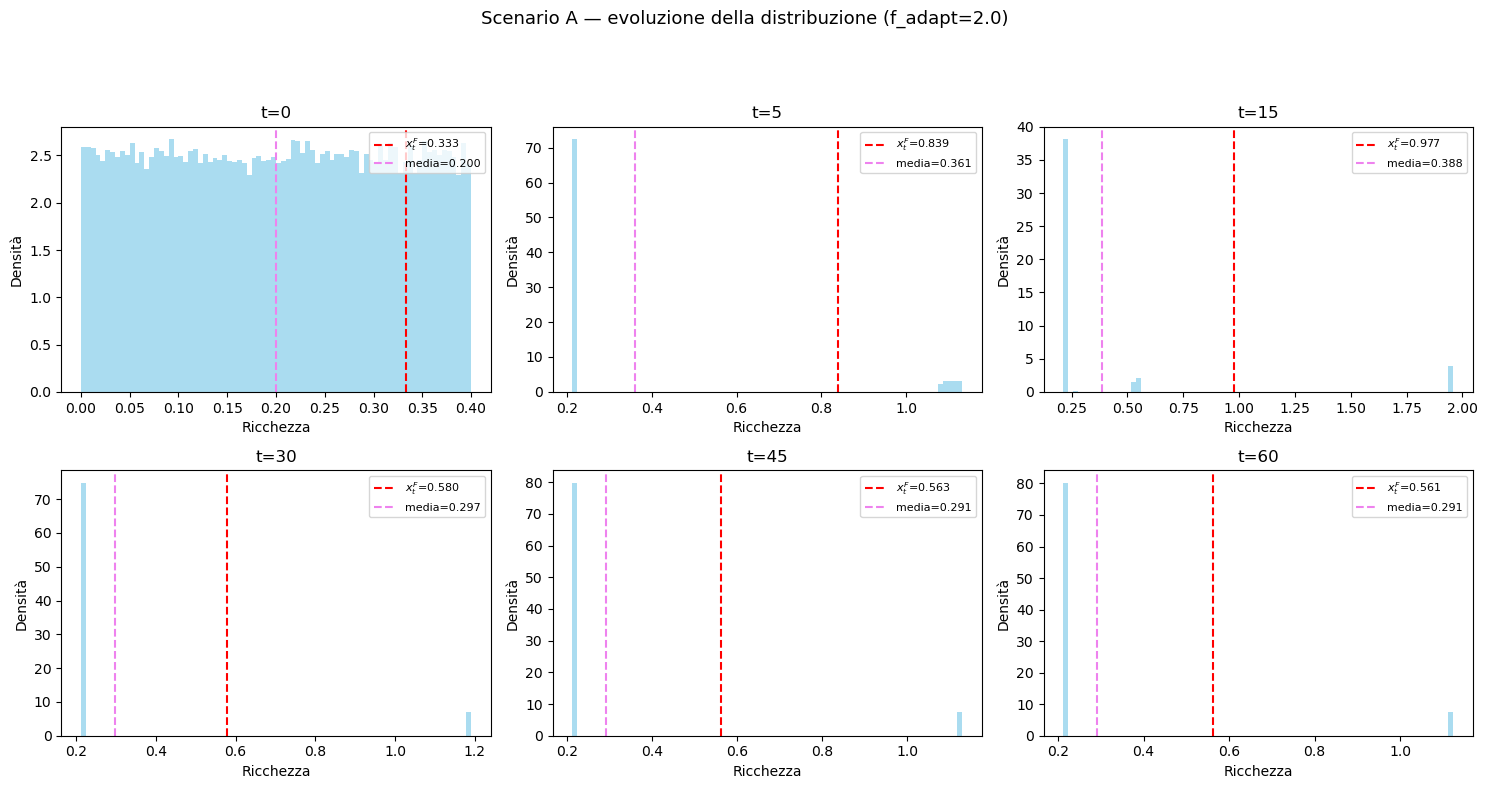

In [ ]:
f_demo = 2.0
r_ = results_A[f_demo]
history, xF_hist = r_['history'], r_['xF']

times = [0, 5, 15, 30, 45, 60]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, t in enumerate(times):
    ax = axes[i]
    mean = np.mean(history[t])
    ax.hist(history[t], bins=80, alpha=0.7, density=True, color='skyblue')
    ax.axvline(xF_hist[t], color='red', linestyle='--', label=fr"$x_t^F$={xF_hist[t]:.3f}")
    ax.axvline(mean, color='violet', linestyle='--', label=f"media={mean:.3f}")
    ax.set_title(f"t={t}")
    ax.set_xlabel("Ricchezza"); ax.set_ylabel("Densità")
    ax.legend(fontsize=8)

fig.suptitle(f"Scenario A — evoluzione della distribuzione (f_adapt={f_demo})",
             fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


## Scenario B — $n_0^P > n^*$: la soglia endogena può arginare l'esplosione

Ora parto da una distribuzione iniziale più ricca ($L=3$), tale che $n_0^P \approx 0.88 > n^*$.
Con soglia FISSA questo cade nel regime `poor_attractor_and_explosion`: la parte destra della
distribuzione diverge. Voglio vedere se una soglia che si alza al crescere dell'output — cioè
diventa via via più difficile investire in adattamento — può impedire la divergenza.

In [28]:
T_B = 40
L_B = 3.0
f_values_B = [0.0, 0.5, 2.0, 5.0]

results_B = {}
for f_adapt in f_values_B:
    np.random.seed(2)
    history, xF_hist, np_hist, X_hist = simulate_endogenous_det(
        lambda N: uniform_initial(N, low=0, high=L_B),
        update_wealth, T_B, f_adapt, N=N, threshold_mode='log')
    results_B[f_adapt] = dict(history=history, xF=xF_hist, n_p=np_hist, X=X_hist)
    print(f"f_adapt={f_adapt:5.2f}  n_p0={np_hist[0]:.3f}  n_p_final={np_hist[-1]:.3f}  "
          f"xF_final={xF_hist[-1]:.4g}  X_final={X_hist[-1]:.4g}")


f_adapt= 0.00  n_p0=0.888  n_p_final=0.888  xF_final=0.3333  X_final=1.457e+12
f_adapt= 0.50  n_p0=0.888  n_p_final=0.313  xF_final=1.029  X_final=2.291
f_adapt= 2.00  n_p0=0.888  n_p_final=0.000  xF_final=1224  X_final=2.938
f_adapt= 5.00  n_p0=0.888  n_p_final=0.000  xF_final=1.126e+08  X_final=2.876


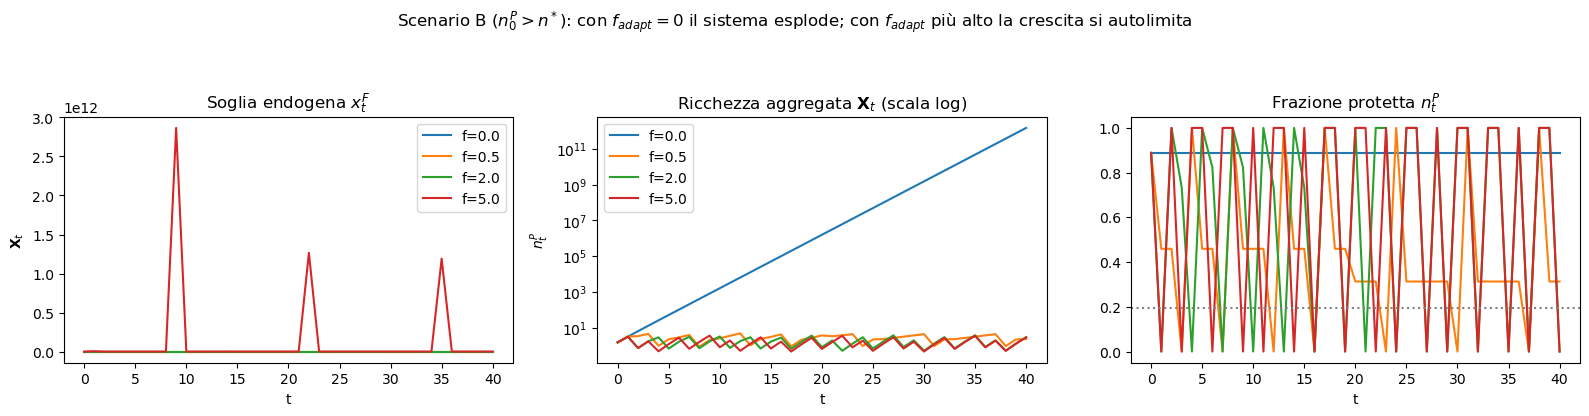

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

for f_adapt in f_values_B:
    r_ = results_B[f_adapt]
    axes[0].plot(r_['xF'], label=f"f={f_adapt}")
    axes[1].plot(r_['X'], label=f"f={f_adapt}")
    axes[2].plot(r_['n_p'], label=f"f={f_adapt}")

axes[0].set_title(r"Soglia endogena $x_t^F$")
axes[0].set_xlabel("t"); axes[0].set_ylabel(r"$x_t^F$"); axes[0].legend()

axes[1].set_yscale('log')
axes[1].set_title(r"Ricchezza aggregata $\mathbf{X}_t$ (scala log)")
axes[1].set_xlabel("t"); axes[0].set_ylabel(r"$\mathbf{X}_t$"); axes[0].legend()

axes[2].axhline(0.1954, color='gray', linestyle=':', label=r"$n^*$ (soglia fissa, expected)")
axes[2].set_title(r"Frazione protetta $n_t^P$")
axes[2].set_xlabel("t"); axes[1].set_ylabel(r"$n_t^P$"); axes[1].legend()

fig.suptitle(r"Scenario B ($n_0^P > n^*$): con $f_{adapt}=0$ il sistema esplode; "
             r"con $f_{adapt}$ più alto la crescita si autolimita", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


Ripeto lo stesso Scenario B con `threshold_mode='corner'`, per vedere se e come l'esito
cambia rispetto a `'log'`.

In [33]:
results_B_corner = {}
for f_adapt in f_values_B:
    np.random.seed(2)
    history, xF_hist, np_hist, X_hist = simulate_endogenous_det(
        lambda N: uniform_initial(N, low=0, high=L_B),
        update_wealth, T_B, f_adapt, N=N, threshold_mode='corner')
    results_B_corner[f_adapt] = dict(history=history, xF=xF_hist, n_p=np_hist, X=X_hist)
    print(f"f_adapt={f_adapt:5.2f}  n_p0={np_hist[0]:.3f}  n_p_final={np_hist[-1]:.3f}  "
          f"xF_final={xF_hist[-1]:.4g}  X_final={X_hist[-1]:.4g}")


f_adapt= 0.00  n_p0=0.888  n_p_final=0.888  xF_final=0.3333  X_final=1.457e+12
f_adapt= 0.50  n_p0=0.888  n_p_final=0.494  xF_final=4.987e+06  X_final=3.491e+06
f_adapt= 2.00  n_p0=0.888  n_p_final=1.000  xF_final=0  X_final=0.3296
f_adapt= 5.00  n_p0=0.888  n_p_final=1.000  xF_final=0  X_final=0.3296


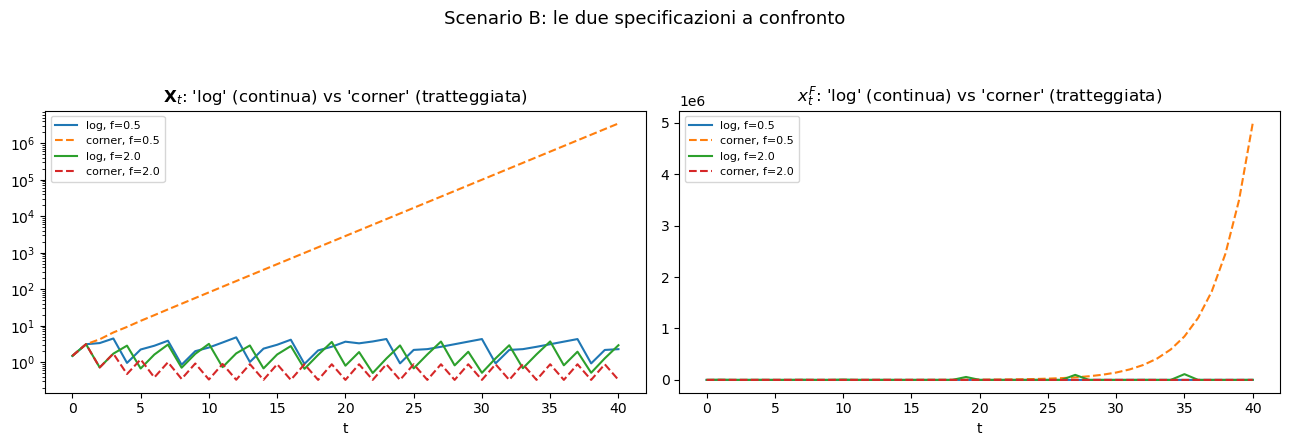

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for f_adapt in [0.5, 2.0]:
    axes[0].plot(results_B[f_adapt]['X'], label=f"log, f={f_adapt}")
    axes[0].plot(results_B_corner[f_adapt]['X'], '--', label=f"corner, f={f_adapt}")
    axes[1].plot(results_B[f_adapt]['xF'], label=f"log, f={f_adapt}")
    axes[1].plot(results_B_corner[f_adapt]['xF'], '--', label=f"corner, f={f_adapt}")

axes[0].set_yscale('log')
axes[0].set_title(r"$\mathbf{X}_t$: 'log' (continua) vs 'corner' (tratteggiata)")
axes[0].set_xlabel("t"); axes[0].legend(fontsize=8)

axes[1].set_title(r"$x_t^F$: 'log' (continua) vs 'corner' (tratteggiata)")
axes[1].set_xlabel("t"); axes[1].legend(fontsize=8)

fig.suptitle("Scenario B: le due specificazioni a confronto", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


Entrambe le specificazioni riescono ad arginare l'esplosione per $f_{adapt}$ sufficientemente
alto, ma con dinamiche quantitativamente diverse (`'corner'` tende a "restare bloccata" a $x_t^F=0$
per più periodi quando $\mathbf{X}_t$ scende, `'log'` si muove sempre in modo liscio) — nessuna
delle due è "più corretta" in astratto, sono due modellizzazioni diverse dello stesso vincolo
$x_t^F\ge0$, con implicazioni analitiche diverse (si veda la sezione precedente).

**Lettura del risultato:** per `f_adapt=0` (soglia fissa) $\mathbf{X}_t$ cresce di vari
ordini di grandezza (coerente con il regime esplosivo previsto dal `.tex` per $n_0^P>n^*$). Per
$f_{adapt}>0$ la crescita esplosiva viene comunque arginata, ma **non** attraverso una semplice
discesa monotona di $n_t^P$ sotto $n^*$: guardando la traiettoria passo-passo (si veda sotto per
$f_{adapt}=2.0$), il sistema entra in un **regime oscillatorio tipo boom-bust**, in cui $n_t^P$
alterna fasi vicine a $1$ (quasi tutti protetti, $\mathbf{X}_t$ cresce) a fasi vicine a $0$ (quasi
nessuno protetto, $\mathbf{X}_t$ crolla), con $x_t^F$ che si impenna nelle fasi di boom e ricade
in quelle di bust. Questo è un effetto di retroazione negativa **ritardata** (la soglia reagisce
alla ricchezza con un periodo di ritardo, potendo quindi "overshoot"), non un risultato dimostrato
algebricamente nel `.tex`: qui è solo mostrato per via numerica, su queste particolari condizioni
iniziali e questi parametri — non generalizzo oltre quanto osservato in queste simulazioni, e non
ho verificato se si tratti di un vero ciclo limite nel senso dei sistemi dinamici o di un
transitorio molto lungo.

In [35]:
for t in range(0, T_B + 1):
    print(f"t={t:2d}  n_p={results_B[2.0]['n_p'][t]:.3f}  "
          f"xF={results_B[2.0]['xF'][t]:9.4g}  X={results_B[2.0]['X'][t]:.4g}")


t= 0  n_p=0.888  xF=   0.3333  X=1.501
t= 1  n_p=0.000  xF=     3622  X=3.128
t= 2  n_p=1.000  xF=  0.00389  X=0.7223
t= 3  n_p=0.733  xF=    1.213  X=1.727
t= 4  n_p=0.000  xF=      788  X=2.861
t= 5  n_p=1.000  xF= 0.002979  X=0.6756
t= 6  n_p=0.824  xF=   0.6836  X=1.627
t= 7  n_p=0.000  xF=     2452  X=3.059
t= 8  n_p=1.000  xF= 0.003633  X=0.7104
t= 9  n_p=0.824  xF=    1.048  X=1.702
t=10  n_p=0.000  xF=     5559  X=3.203
t=11  n_p=1.000  xF= 0.004193  X=0.7354
t=12  n_p=0.733  xF=    1.425  X=1.755
t=13  n_p=0.000  xF=    937.6  X=2.891
t=14  n_p=1.000  xF= 0.003071  X=0.6809
t=15  n_p=0.733  xF=   0.7297  X=1.638
t=16  n_p=0.000  xF=    509.7  X=2.784
t=17  n_p=1.000  xF=  0.00276  X=0.6623
t=18  n_p=1.000  xF=   0.5803  X=1.598
t=19  n_p=0.000  xF=5.691e+04  X=3.61
t=20  n_p=1.000  xF= 0.006299  X=0.8067
t=21  n_p=0.000  xF=    3.418  X=1.909
t=22  n_p=1.000  xF=  0.00115  X=0.509
t=23  n_p=1.000  xF=  0.08835  X=1.269
t=24  n_p=0.000  xF=    996.6  X=2.902
t=25  n_p=1.000  xF

## Confronto diretto: soglia fissa (`simulate_det`) vs soglia endogena

Stesso scenario B, stesse condizioni iniziali: uso `simulate_det` (soglia fissa, già presente
nel progetto) come benchmark, a fianco della versione endogena con `f_adapt=2.0`,
`threshold_mode='log'` (default).

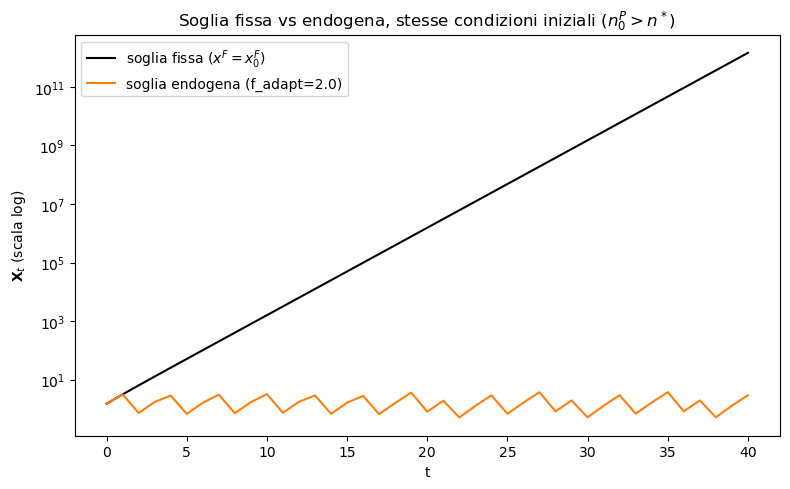

X finale — soglia fissa: 1.457e+12   soglia endogena (f=2.0): 2.938


In [36]:
np.random.seed(2)
history_fixed = simulate_det(lambda N: uniform_initial(N, low=0, high=L_B),
                              update_wealth, T_B, N=N)
X_fixed = [np.mean(h) for h in history_fixed]
n_p_fixed = [np.mean(h > _par.xF) for h in history_fixed]

f_compare = 2.0
r_endo = results_B[f_compare]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(X_fixed, label="soglia fissa ($x^F=x^F_0$)", color='black')
ax.plot(r_endo['X'], label=f"soglia endogena (f_adapt={f_compare})", color='tab:orange')
ax.set_yscale('log')
ax.set_xlabel("t"); ax.set_ylabel(r"$\mathbf{X}_t$ (scala log)")
ax.set_title("Soglia fissa vs endogena, stesse condizioni iniziali ($n_0^P>n^*$)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"X finale — soglia fissa: {X_fixed[-1]:.4g}   soglia endogena (f={f_compare}): {r_endo['X'][-1]:.4g}")


## Versione con shock stocastici

Ripeto lo Scenario B con `simulate_endogenous_shock`, che ad ogni periodo estrae una
realizzazione effettiva degli shock $\lambda_p,\lambda_{up}$ (come in `simulations_shock.py`),
invece di usare le produttività attese $E[A_p], E[A_{up}]$.

In [37]:
p_shock = _par.p
gamma_p_shock = _par.gamma_p
gamma_up_shock = _par.gamma_up

f_shock_values = [0.0, 2.0, 5.0]
results_shock = {}
for f_adapt in f_shock_values:
    np.random.seed(3)
    history, xF_hist, np_hist, X_hist = simulate_endogenous_shock(
        lambda N: uniform_initial(N, low=0, high=L_B),
        update_wealth, T_B, f_adapt, N=N)
    results_shock[f_adapt] = dict(history=history, xF=xF_hist, n_p=np_hist, X=X_hist)
    print(f"f_adapt={f_adapt:5.2f}  n_p0={np_hist[0]:.3f}  n_p_final={np_hist[-1]:.3f}  "
          f"xF_final={xF_hist[-1]:.4g}  X_final={X_hist[-1]:.4g}")


f_adapt= 0.00  n_p0=0.890  n_p_final=1.000  xF_final=0.3333  X_final=6.071e+13
f_adapt= 2.00  n_p0=0.890  n_p_final=0.000  xF_final=48.77  X_final=2.372
f_adapt= 5.00  n_p0=0.890  n_p_final=0.000  xF_final=6.22e+04  X_final=2.349


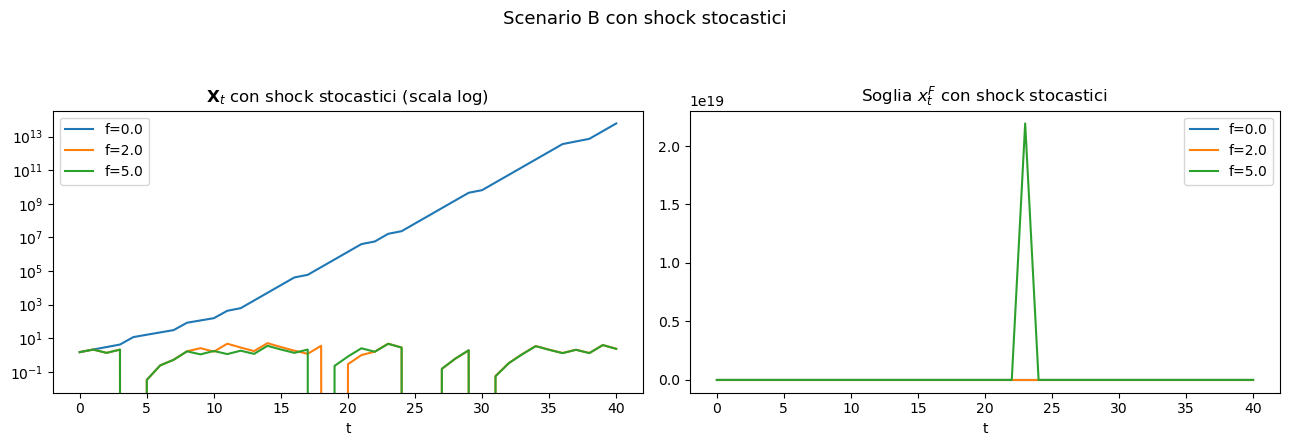

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for f_adapt in f_shock_values:
    r_ = results_shock[f_adapt]
    axes[0].plot(r_['X'], label=f"f={f_adapt}")
    axes[1].plot(r_['xF'], label=f"f={f_adapt}")

axes[0].set_yscale('log')
axes[0].set_title(r"$\mathbf{X}_t$ con shock stocastici (scala log)")
axes[0].set_xlabel("t"); axes[0].legend()

axes[1].set_title(r"Soglia $x_t^F$ con shock stocastici")
axes[1].set_xlabel("t"); axes[1].legend()

fig.suptitle("Scenario B con shock stocastici", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


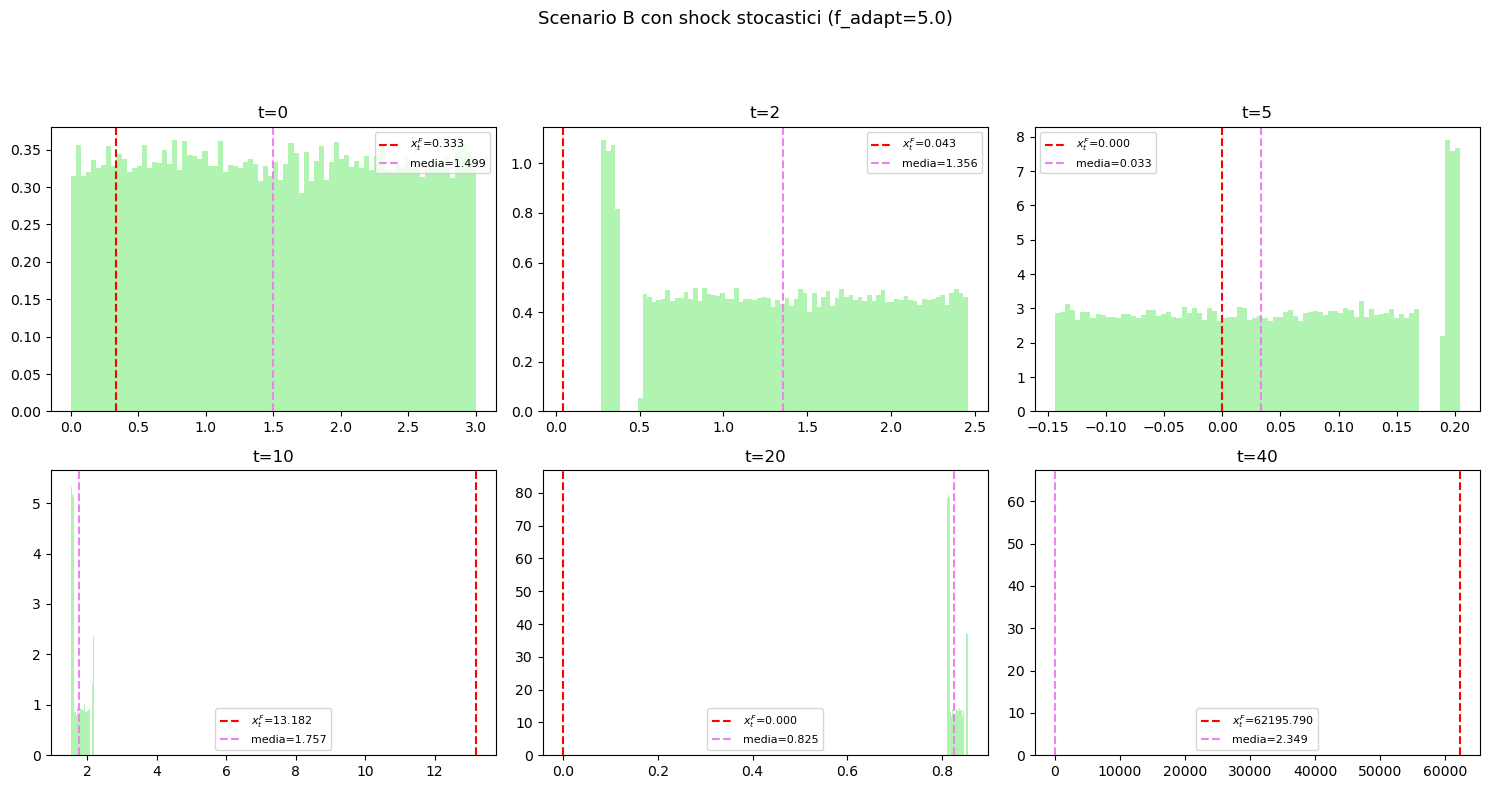

In [39]:
f_demo_shock = 5.0
r_ = results_shock[f_demo_shock]
history, xF_hist = r_['history'], r_['xF']

times = [0, 2, 5, 10, 20, 40]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, t in enumerate(times):
    ax = axes[i]
    mean = np.mean(history[t])
    ax.hist(history[t], bins=80, alpha=0.7, density=True, color='lightgreen')
    ax.axvline(xF_hist[t], color='red', linestyle='--', label=fr"$x_t^F$={xF_hist[t]:.3f}")
    ax.axvline(mean, color='violet', linestyle='--', label=f"media={mean:.3f}")
    ax.set_title(f"t={t}")
    ax.legend(fontsize=8)

fig.suptitle(f"Scenario B con shock stocastici (f_adapt={f_demo_shock})", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


## Mappa empirica $n^P_{t+1} = H(n^P_t)$

Il `.tex` (subparagraph "Dynamics of $n^P_t$") definisce implicitamente una mappa
$n^P_{t+1}=H(n^P_t)$ che incorpora la dinamica microeconomica, l'aggregazione in
$\mathbf{X}_t$, e la retroazione sulla soglia — ma non ne dà la forma chiusa. Qui traccio la
sua traiettoria empirica $(n_t^P, n_{t+1}^P)$ lungo una delle simulazioni dello Scenario B, per
visualizzare come il sistema si muove verso il proprio punto fisso.

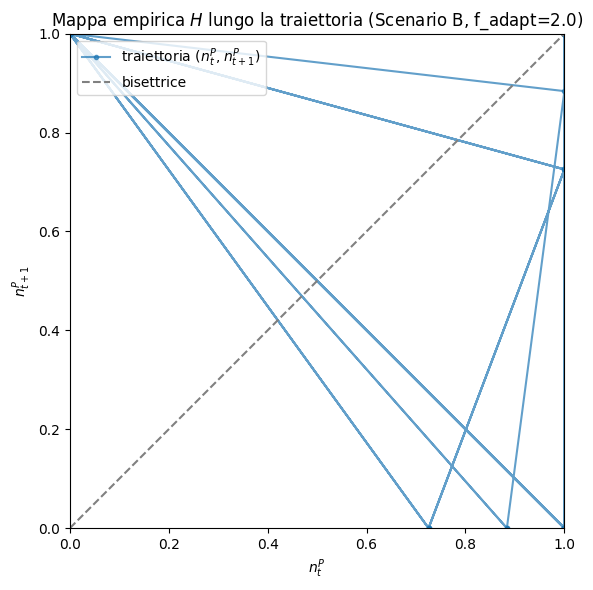

In [18]:
f_map = 2.0
n_p_traj = results_B[f_map]['n_p']
x_pts, y_pts = empirical_H_map(n_p_traj)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x_pts, y_pts, '-o', color='tab:blue', markersize=3, alpha=0.7, label=r"traiettoria $(n_t^P, n_{t+1}^P)$")
lims = [0, 1]
ax.plot(lims, lims, '--', color='gray', label="bisettrice")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel(r"$n_t^P$"); ax.set_ylabel(r"$n_{t+1}^P$")
ax.set_title(fr"Mappa empirica $H$ lungo la traiettoria (Scenario B, f_adapt={f_map})")
ax.legend()
ax.set_aspect('equal')
plt.tight_layout()
plt.show()


## Note conclusive

- Tutte le equazioni usate qui sono quelle della sezione "Endogenous adaptation investment" del
  `Cattaneo_appunti_tesi.tex`; le due correzioni rispetto al testo letterale sono (i) il fattore
  $x$ mancante nell'integrale dell'equazione boxed finale, e (ii) la riparametrizzazione
  positiva di $x_t^F$ (default `'log'`, alternativa `'corner'`), necessaria perché la formula
  additiva originale può diventare negativa — entrambe segnalate esplicitamente sopra, non
  applicate "in silenzio".
- La specificazione `'log'` ($x_t^F = x_0^F e^{f(\mathbf{X}_t-\mathbf{X}_0)/(1-\alpha)}$) è la
  stessa idea, in forma di feedback moltiplicativo, dei fattori di danno/output usati nei modelli
  di integrated assessment (Nordhaus, DICE) per garantire positività per costruzione — si veda il
  paragrafo dedicato che ho scritto per il `.tex`, dove la motivazione è spiegata più in
  dettaglio con riferimento a Nordhaus (2008) e Barrage & Nordhaus (2023).
- `f_adapt` è un parametro libero, non calibrato nel `.tex`: i valori usati qui sono solo per
  esplorazione numerica, non vanno intesi come stime realistiche.
- Il file `.tex` elenca (in un blocco `\begin{comment}`, quindi non ancora citazioni formali nel
  documento) una lista di letteratura sulle soglie mobili / sistemi dinamici piecewise-smooth,
  riportata qui perché richiesto — è quella già presente nel tuo file, non l'ho ampliata:
  - Costas Azariadis, John Stachurski — *Poverty Traps*, cap. 5 (in *Handbook of Economic Growth*)
  - *Adaptive complex contagions and threshold dynamical systems*
  - M. di Bernardo et al. — *Piecewise-smooth Dynamical Systems*
  - *Hidden dynamics for piecewise smooth maps*
  - Mehdi Pourbarat, Neda Abbasi, Roya Makrooni, Mohammad Reza Molaei — *Chaos in
    One-dimensional Piecewise Smooth Dynamical Systems*
  - *Exploring nonlinear chaotic systems with applications in stochastic processes*
  - *Stochastic dynamics II: Finite random dynamical systems, linear representation, and
    entropy production*

  Non ho verificato questi riferimenti (titoli/autori) al di fuori di quanto scritto nel tuo
  file: se ti servono per la bibliografia della tesi, andrebbero controllati e citati in formato
  completo con la fonte primaria.
- Gli "esperimenti" mostrati sopra (Scenario A, Scenario B, effetto auto-limitante di $f_{adapt}$
  grande, confronto `'log'`/`'corner'`) sono osservazioni empiriche da queste simulazioni con
  questi parametri, non risultati dimostrati analiticamente nel `.tex`: vanno trattati come
  spunti da verificare, non come conclusioni della tesi.
